## 0. Preamble

In this lab, we will explore two methods for unsupervised visual feature learning:
- patch-based codebook learning with k-means,
- convolutional auto-encoders.

We will use the features to feed a simple linear classifier to perform image classification on a subset of the CIFAR-10 dataset. Our goal is to see how far we can get by training a simple supervised linear classifier, and some additional unlabeled data.

We will use the default logistic regression classifier of scikit-learn as a linear classifier. The classification task will be tough for the classifier, so scikit-learn may raise some warning when the optimization algorithm fails to converge. The warning can be ignored; adjusting the number of iterations for the algorithm would not improve the performance. The goal here is not to get the best supervised classifier, but to see _how much we can improve a basic classifier without additional supervision_.

The code for the required library imports for the lab and some basic I/O functions is provided below.

In [ ]:
## Imports
import pickle
import numpy as np
import skimage.io as skio
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow.keras as ks
import sklearn.linear_model as sklm
import sklearn.model_selection as skms
from tqdm import tqdm
from sklearn.exceptions import ConvergenceWarning
import warnings

warnings.filterwarnings("ignore", category=ConvergenceWarning)


## Set Keras default precision
tf.keras.backend.set_floatx('float32')

## IO functions
# Read images
def cifar_load_data( file ):
        '''Loads CIFAR data file.

        :param file: Path to the data file
        :type file: String
        
        :return: Tuple (data, label), with:
                 - data as a Numpy array of shape (nb_samples, 32, 32, 3)
                 - labels as a Numpy array of Strings aligned with the data array
        '''
        with open(file, 'rb') as fo:
            data = pickle.load(fo, encoding='bytes')
        images = np.zeros( (len(data[b'data']), 32, 32, 3), dtype=data[b'data'].dtype )
        for i in range(len(data[b'data'])):
                images[i,:,:,:] =  np.reshape( np.reshape(data[b'data'][i], (1024, 3), 'F'), (32, 32, 3) )
        return images/255., np.array(data[b'labels'])
    
# Display functions        
def imshow_rgb(im, file=None):
    '''
    Displays an RGB image and (optionnally) saves it to a file.
    Note: the displayed figure is saved (with axes, etc.), not the actual image.
    
    :param im: Image to display / save
    :param file: Path to the file to save the image. If set to None, the image is not
                 saved (default = None).
    :type im: Numpy array of shape (h, w, 3)
    :type file: String
    '''
    plt.figure()
    plt.imshow(im, vmin=0., vmax=1.)
    if file is not None:
        plt.savefig(file, bbox_inches='tight')

2026-01-05 21:24:58.122739: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-05 21:24:58.208931: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-01-05 21:25:00.062786: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


When working on unsupervised feature learning, the good practice is to train the feature extractor and the final classifier on independent datasets: since the feature extractor will be optimized on the data set it is trained with, the classifier should be trained and (especially) tested on an independent data set, to prevent overestimating the performance measure.

We will use two subsets of CIFAR-10 in the experiments:
- the first batch `data_batch_1` will be used to evaluate classifiers; it will be referred to as the classification dataset;
- the second batch `data_batch_2` will be used to train the unsupervised feature extractors; it will be referred to as the feature learning dataset.

Run the following code to load the datasets.

In [2]:
# Classification dataset
clf_images, clf_labels = cifar_load_data('data/cifar10/data_batch_1')
# Feature learning dataset (labels can be dropped here!)
feature_train_images, _ = cifar_load_data('data/cifar10/data_batch_2')

## 1. Pre-processing

To make it easier to learn robust features, we will first normalize the luminosity and contrast of images. For a given image $I$, the normalization function is as follows:
$$\hat{I}[i,j,c] = \max\left(\min\left(\frac{I[i,j,c] - \mu_{I}}{3.\sigma_I}, 1\right), -1\right)$$
with $I[i,j,c]$ the pixel value at location $(i,j)$ in channel $c$, $\hat{I}[i,j,c]$ the normalized pixel value, $\mu_I$ the average pixel value in $I$, and $\sigma_I$ the standard deviation of pixel values in $I$.

Normalized pixel values lie in the range $[-1,1]$.

All experiments in this lab will be performed using the normalized data.

**Question 1.** Write a function to normalize pixel values in a dataset of images.

In [3]:
def normalize_images(images):
    '''
    Normalizes pixel values of images using the given formula.
    
    :param images: Input images as a NumPy array of shape (n, h, w, c)
    :return: Normalized images as a NumPy array of same shape
    '''
    # Calculate mean and std for each image (keep channel dimension)
    mean = np.mean(images, axis=(1, 2, 3), keepdims=True)
    std = np.std(images, axis=(1, 2, 3), keepdims=True)
    
    # Formula
    normalized = (images - mean) / (3.0 * std + 1e-8)  # Add epsilon to avoid division by zero
    normalized = np.clip(normalized, -1.0, 1.0)
    
    return normalized

**Question 2.** Normalize the images of the two datasets.

In [4]:
# Normalize the classification dataset
clf_images_normalized = normalize_images(clf_images)

# Normalize the feature learning dataset
feature_train_images_normalized = normalize_images(feature_train_images)

**Question 3.** Visualize some images before and after normalizing and comment on the effect of this normalization procedure.

_Note: When visualizing normalized images, make sure to shift the range of pixels back to $[0,1]$ so that the `imshow_rgb()` function can display them properly:_ $\tilde{I}[i,j,c] = \frac{\hat{I}[i,j,c] + 1}{2}$ _._

Mean of original image 0: 0.40567555147058826, Std: 0.20381850341830213
Mean of normalized image 0: -4.163336342344337e-17, Std: 0.33333332788186015
Mean of original image 1: 0.5111660028594771, Std: 0.23717334049548047
Mean of normalized image 1: 1.850371707708594e-17, Std: 0.3333333286485272
Mean of original image 2: 0.5244727839052288, Std: 0.32377743379113044
Mean of normalized image 2: -1.850371707708594e-17, Std: 0.33333332990162073
Mean of original image 3: 0.31460503472222223, Std: 0.1430271224612941
Mean of normalized image 3: -0.0039047285409332436, Std: 0.3198096714877701


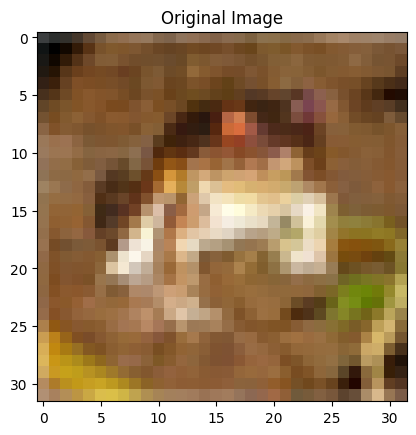

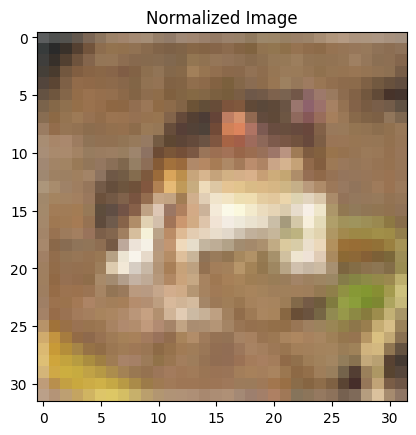

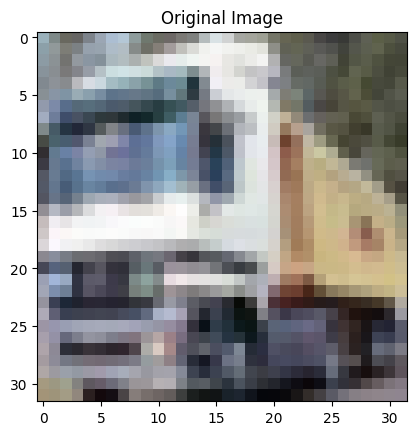

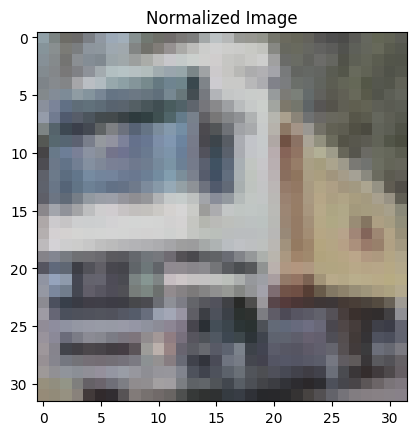

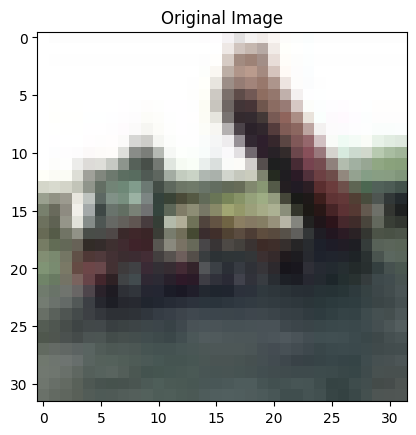

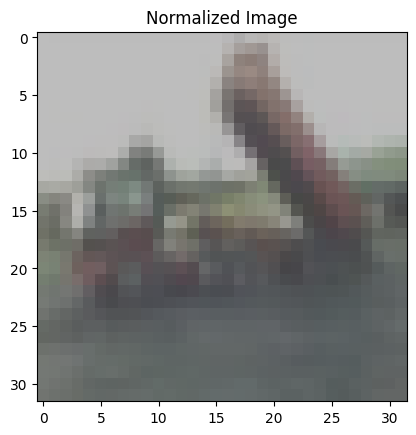

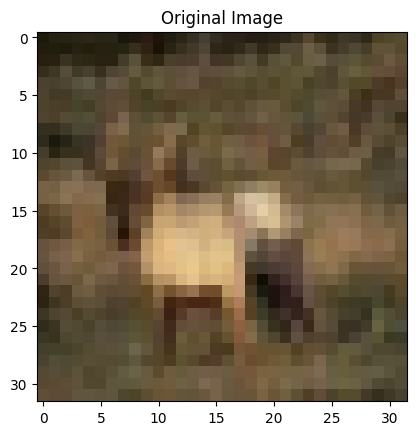

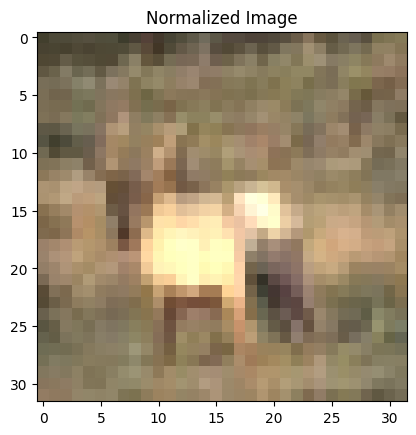

In [5]:
sample_indices = [0, 1, 2, 3]

for idx in sample_indices:
    # Original image
    print(f"Mean of original image {idx}: {np.mean(clf_images[idx])}, Std: {np.std(clf_images[idx])}")
    imshow_rgb(clf_images[idx], file=f'original_{idx}.png')
    plt.title('Original Image')
    
    # Normalized image (shifted back to [0,1] range for display)
    normalized_shifted = (clf_images_normalized[idx] + 1) / 2
    print(f"Mean of normalized image {idx}: {np.mean(clf_images_normalized[idx])}, Std: {np.std(clf_images_normalized[idx])}")
    imshow_rgb(normalized_shifted, file=f'normalized_{idx}.png')
    plt.title('Normalized Image')


**Comment on the effect:**

The normalization procedure standardizes both the luminosity and contrast of the images. After normalization:

1. Each image has pixel values centered around zero mean.
2. The standard deviation of pixel values is scaled to approximately 1/3.
3. Pixel values are clipped to the range \([-1, 1]\), reducing the influence of outliers.

Visually, this results in images with more uniform brightness and contrast, making them appear more consistent across the dataset. This consistency helps feature learning algorithms by minimizing variations due to lighting or contrast, allowing the models to focus on the actual content of the images rather than irrelevant differences.

## 2. Baseline

To analyze the results of feature learning, we first need some baseline performance. We will use a basic "feature-free" linear classifier as a baseline system.

**Question 4.** Build a logistic regression classifier (using the `LogisticRegression` class of scikit-learn, with default parameters). Evaluate its performance on the classification dataset when using directly the normalized images as input data, using 5-fold stratified cross-validation (evaluation measure: accuracy).

_Tip: the `cross_val_score()` function of scikit-learn can take care of the stratified cross-validation for you._

In [6]:
# Prepare the data for logistic regression
# Flatten the images from (n_samples, 32, 32, 3) to (n_samples, 3072)
X = clf_images_normalized.reshape(len(clf_images_normalized), -1)
y = clf_labels

lr_classifier = sklm.LogisticRegression()

cv_scores = skms.cross_val_score(lr_classifier, X, y, cv=5, scoring='accuracy')

/home/layesekou/masterds/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/layesekou/masterds/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules

In [7]:
mean_accuracy = np.mean(cv_scores)
std_accuracy = np.std(cv_scores)

print(f"Baseline logistic regression performance:")
print(f"Mean accuracy: {mean_accuracy:.4f}")
print(f"Standard deviation: {std_accuracy:.4f}")
print(f"Individual fold scores: {cv_scores}")

Baseline logistic regression performance:
Mean accuracy: 0.3048
Standard deviation: 0.0059
Individual fold scores: [0.305  0.304  0.3015 0.298  0.3155]


## 3. Feature extraction with k-means

We will first design a patch-based feature extractor based on k-means, and test it with a linear classifier. We recall the procedure for the patch-based unsupervised learning seen in class.

__Training:__ Given a training set $D$ of images 
1. Extract $n$ random patches from training images $D$.
1. Flatten the patches into 1-D vectors.
1. Fit the k-means model on the training vectors.
1. Use the centroids as a codebook.

__Inference:__ Given an image $I$
1. Densely sample patches in $I$.
1. Flatten the patches into 1-D vectors.
1. Assign each patch to its nearest centroid and compute the representation vector for this patch.

__Pooling:__ Pool the feature vectors for Image $I$ into a single 1-D vector to be fed to the classifier. We will use sum pooling here:
$$f(I) = \sum_i f^{(i)}$$
with $f^{(i)}$ the feature vector obtained for patch $p_i$ of image $I$, and $f(I)$ the final feature vector for image $I$.

The code below provides functions to sample random patches from a dataset, and to sample dense patches from a single image.

_Note: Extracting dense patches at once over the whole dataset is not recommended as it would consume a large amount of RAM._

In [8]:
def sample_patches_random(imgs, s, n_samples):
    '''Samples random square patches of given size from a dataset of images.
    
    :param imgs: Images from which patches are sampled
    :param s: Patch height/width. Patches have final size (s x s)
    :param n_samples: Number of patches to sample
    :type imgs: Numpy array of shape (n, h, w, c) with n the number
                of images, (h,w) the image size, and c the number of channels
    :type s: Int
    :type n_samples: Int
    
    :return: Array of n_samples image patches of size (s x s)
    :rtype:Numpy array of shape (n_samples, s, s, c)
    '''
    n, h, w = imgs.shape[:3]
    hs = s // 2
    patches = np.zeros((n_samples, s, s) + imgs.shape[3:], dtype=np.float32)
    for si in range(n_samples):
        ii = np.random.randint(n)
        pi = np.random.randint(hs,h-hs)
        pj = np.random.randint(hs,w-hs)
        patches[si,...] = imgs[ii,pi-hs:pi+hs+1,pj-hs:pj+hs+1]
    return patches

def sample_patches_dense(img, s):
    '''
    Dense sampling of (overlapping) square patches of size (s x s) from image img.
    
    :param img: Image from which patches are sampled
    :param s: Height/width of the patches. Final patches have size (s x s)
    :type img: Numpy array of shape (h, w, c) with h and w the height and
               width of the image, respectively, and c its number of channels
    :type s: Int
    
    :return: Patches of size (s x s) extracted from img
    :rtype: Numpy array of shape (n, s, s, c), with n the number of patches
    '''
    h, w, _ = img.shape
    hs = s // 2
    patches = np.zeros(((h-2*hs)*(w-2*hs), s, s) + img.shape[2:], dtype=np.float32)
    for j in range(hs, h-hs):
        for k in range(hs, w-hs):
            patches[(j-hs)*(h-2*hs)+(k-hs),...] = img[j-hs:j+hs+1,k-hs:k+hs+1]
    return patches

We will use the damped k-means algorithm from [(Coates et al., 2012)](https://www-cs.stanford.edu/~acoates/papers/coatesng_nntot2012.pdf) as it runs faster than scikit-learn's implementation and suits well visual data.

The algorithm uses the cosine similarity as a distance metric (so, it maximizes the metric for assigning vectors to clusters), and adds momnetum to centroid updates. Cosine similarity is equivalent to the L2 distance / MSE when the vectors are L2-normalized. The centroids provided by the algorithm are L2-normalized.

Feature vectors output by the model at inference time have the form $f = (f_1, f_2, \ldots, f_k)$, with:
$$f_i = \left\{\begin{array}{cl}
|\cos(x_j, c_i)| & \text{if }c_i = \arg\max_{c_k \in C}|\cos(x_j,c_k)|\\
0 & \text{otherwise}\\
\end{array}\right.$$
where $x_j$ is the input vector and $c_i \in C$ is a centroid.

The code below provides a basic implementation of the training and inference algorithms for damped k-means.

[(Coates et al., 2012) Adam Coates and Andrew Y. Ng. Learning Feature Representations with K-means. Neural
Networks: Tricks of the Trade, 2nd edn, Springer LNCS 7700, 2012.](https://www-cs.stanford.edu/~acoates/papers/coatesng_nntot2012.pdf)

In [9]:
def damped_kmeans_inference(data, centroids):
    '''
    Inference procedure for damped k-means.
    
    :param data: Input vectors
    :param centroids: Centroids computed with damped k-means
    :type data: Numpy array of shape (n,d), with n the number
                of vectors and d their length
    :type centroids: Numpy array of shape (k,d), with k the
                     number of centroids and d their length
    
    :return: One feature vector of length k for each of the
             n input vectors
    :rtype: Numpy array of shape (n, k)
    '''
    n = len(data)
    nc = len(centroids)
    
    # L2-normalize inputs
    data = (data.T / (np.linalg.norm(data, axis=1) + 1e-7)).T

    # initialize output (assignment) array
    output = np.zeros((n, nc), dtype=np.float32)

    # Compute cosine distance
    dists_to_centroids = data.dot(centroids.T)
    # Pick the closest centroid for each sample
    max_cluster_indices = np.argmax(np.abs(dists_to_centroids), axis=1)
    # Compute output feature vectors
    output[np.arange(n),max_cluster_indices] = dists_to_centroids[np.arange(n),max_cluster_indices]

    return output 
    
def damped_kmeans_train(data, nb_clusters, nb_iter=10):
    '''
    Training procedure for damped k-means.
    
    :param data: Input vectors
    :param nb_clusters: Number of clusters to build (k)
    :param nb_iter: Number of iterations
    :type data: 2-Dimensional Numpy array of shape (n,d), with
                n the number of vectors and d their dimensionality
    :type nb_clusters: Int
    :type nb_iter: Int
    
    :return: Centroids of the clusters
    :rtype: 2-dimensional Numpy array of shape (nb_clusters, d)
    '''
    n, d = data.shape
    data = (data.T / (np.linalg.norm(data, axis=1) + 1e-7)).T
    centroids = np.zeros((nb_clusters, d), dtype=np.float32)
    assignments = np.zeros((n, nb_clusters), dtype=np.float32)
    
    # initialize clusters
    centroids[...] = data[np.random.permutation(np.arange(len(data)))[:nb_clusters]]

    # optimize
    for it in range(nb_iter):
        # assign samples to clusters
        dists_to_centroids = data.dot(centroids.T)
        max_cluster_indices = np.argmax(np.abs(dists_to_centroids), axis=1)
        assignments[...] = 0
        assignments[np.arange(n),max_cluster_indices] = dists_to_centroids[np.arange(n),max_cluster_indices]

        # update centroids
        centroids = assignments.T.dot(data) + centroids
        centroids = (centroids.T / (np.linalg.norm(centroids, axis=1) + 1e-7)).T

    return centroids

**Question 5.** Use damped k-means to compute a codebook of $k = 256$ codewords from 200000 patches of size $5 \times 5$ extracted from the feature training dataset.

In [10]:
patch_size = 5
num_clusters = 256
num_patches = 200000

patches = sample_patches_random(feature_train_images_normalized, patch_size, num_patches)

# Flatten the patches into 1-D vectors
# Shape: (num_patches, patch_size * patch_size * 3)
patches_flat = patches.reshape(num_patches, -1)

centroids = damped_kmeans_train(patches_flat, num_clusters, nb_iter=10)

print(f"Codebook computed: {centroids.shape}")
print(f"Number of centroids: {centroids.shape[0]}")
print(f"Centroid dimensionality: {centroids.shape[1]}")

Codebook computed: (256, 75)
Number of centroids: 256
Centroid dimensionality: 75


**Question 6.** The centroids computed by the k-means algorithm correspond to the mean over the patches assigned to their clusters. As such, they can be visualized as image patches. Display some of the centroids of your codebook.

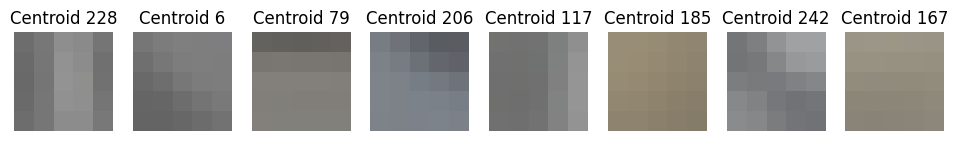

In [11]:
np.random.seed(42)
n_samples = 8  # number of centroids to display
indices = np.random.choice(num_clusters, n_samples, replace=False)

plt.figure(figsize=(12, 2))
for i, idx in enumerate(indices):
    centroid_patch = centroids[idx].reshape(patch_size, patch_size, 3)
    centroid_patch_disp = (centroid_patch + 1) / 2
    plt.subplot(1, n_samples, i + 1)
    plt.imshow(centroid_patch_disp)
    plt.axis('off')
    plt.title(f'Centroid {idx}')
plt.show()

**Question 7.** Comment on the appearance of the codewords (centroids). What do they encode as image features?

The centroids learned by k-means act as a visual vocabulary of basic image patterns found in 5×5 RGB patches. These codewords capture a variety of local visual features:

- **Color averages:** Many centroids correspond to nearly uniform color patches, encoding the dominant color or brightness of local regions.
- **Edge detectors:** Some centroids display clear intensity gradients, often oriented horizontally or vertically, functioning as simple edge detectors.
- **Texture primitives:** As we can see alos, certain centroids represent texture patterns, such as repeated intensity or color variations, capturing local texture information.
- **Color transitions:** A subset of centroids combines color changes with intensity gradients, highlighting boundaries or transitions between different regions.

The codewords encode local color, edge, and texture statistics, providing a compact representation of the fundamental visual structures present in natural images.

**Question 8.** Write a function to compute the feature vector of an image using the codebook learnt with k-means and sum pooling over all local feature vectors of the image.

In [12]:
def compute_kmeans_features(image, centroids, patch_size=5):
    '''
    Compute feature vector for an image using k-means codebook with sum pooling.
    
    :param image: Input image of shape (h, w, 3)
    :param centroids: Codebook centroids of shape (k, d) where d = patch_size*patch_size*3
    :param patch_size: Size of patches to extract (default: 5)
    :return: Feature vector of length k (number of centroids)
    '''
    patches = sample_patches_dense(image, patch_size)
    
    patches_flat = patches.reshape(patches.shape[0], -1)
    
    local_features = damped_kmeans_inference(patches_flat, centroids)
    
    # Apply sum pooling over all patches
    feature_vector = np.sum(local_features, axis=0)
    
    return feature_vector

**Question 9.** Compute the feature vectors for all vectors in the classification dataset.

In [13]:
num_images = len(clf_images_normalized)
num_centroids = centroids.shape[0]

kmeans_features = np.zeros((num_images, num_centroids), dtype=np.float32)

for i in tqdm(range(num_images), desc="Extracting k-means features"):
    kmeans_features[i] = compute_kmeans_features(
        clf_images_normalized[i], 
        centroids, 
        patch_size=5
    )

print(f"Feature vectors computed: {kmeans_features.shape}")

Extracting k-means features: 100%|██████████| 10000/10000 [00:33<00:00, 300.62it/s]

Feature vectors computed: (10000, 256)


**Question 10.** Evaluate the features by training and testing a logistic regression classifier over the classification dataset, using 5-fold stratified cross-validation (evaluation measure: accuracy).

In [15]:
X = kmeans_features
y = clf_labels

lr_classifier = sklm.LogisticRegression()
cv_scores = skms.cross_val_score(lr_classifier, X, y, cv=5, scoring='accuracy')

/home/layesekou/masterds/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/layesekou/masterds/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules

In [16]:
mean_accuracy = np.mean(cv_scores)
std_accuracy = np.std(cv_scores)

print(f"K-means features logistic regression performance:")
print(f"Mean accuracy: {mean_accuracy:.4f}")
print(f"Standard deviation: {std_accuracy:.4f}")
print(f"Individual fold scores: {cv_scores}")

K-means features logistic regression performance:
Mean accuracy: 0.3971
Standard deviation: 0.0103
Individual fold scores: [0.4045 0.3905 0.3825 0.412  0.396 ]


**Question 11.** Comment on the relative performances of the baseline and the feature-based classifier.

he feature-based classifier using k-means features significantly outperforms the baseline logistic regression classifier that uses raw normalized pixels.

The k-means features achieve higher accuracy (39.8%) than raw pixels (30.5%). This shows that the unsupervised patch-based representation provides more useful information for classification than raw pixel values.

## 4. Convolutional auto-encoders (CAE)

**Preliminary note:** In this section, we will need to train neural networks. You may want to use a GPU to make computation faster, e.g. using Google Colab or Grid 5000 (or your own GPU if you are a gamer/bitcoin miner).

In this section, we will evaluate the performance of stacked convolutional auto-encoders in computing unsupervised visual features.

The code below provides a simple one-layer convolutional auto-encoder.

In [17]:
def single_layer_cae(input_shape, kernel_shape, nb_kernels):
    model = ks.Sequential()
    model.add(ks.layers.Input(input_shape))
    model.add(ks.layers.Conv2D(nb_kernels, kernel_shape,
                                    activation='tanh', padding='same'))
    model.add(ks.layers.MaxPooling2D(pool_size=(2,2), strides=(2,2), padding='valid'))
    model.add(ks.layers.Conv2DTranspose(input_shape[-1], kernel_shape,
                                    strides=(2,2), padding='same'))
    lr_schedule = ks.optimizers.schedules.ExponentialDecay(
            initial_learning_rate=1e-3,
            decay_steps=200,
            decay_rate=.9
    )
    optimizer = ks.optimizers.Adam(learning_rate=lr_schedule)
    model.compile(optimizer=optimizer, loss='mse')
    return model

**Question 12.** Justify the choice of padding options in this auto-encoder.

_Tip: Displaying the characteristics of a model (using the `.summary()` method) may help._

The auto-encoder uses `'same'` padding for both the `Conv2D` and `Conv2DTranspose` layers. This choice ensures that the spatial dimensions (height and width) of the feature maps are preserved after each convolution and transposed convolution operation, making it possible to reconstruct the original input image shape after encoding and decoding.

For the `MaxPooling2D` layer, `'valid'` padding is used. This reduces the spatial dimensions by exactly a factor of 2, which is standard for pooling layers and avoids introducing zero-padding artifacts that could distort the feature maps.

We can display the model summary using the `.summary()` method to confirm the output shapes at each layer and verify that the encoder and decoder are symmetric.

In [20]:
# Model summary
cae_model = single_layer_cae((32, 32, 3), (5, 5), 64)
cae_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 3)      │         4,803 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,667 (37.76 KB)

 Trainable params: 9,667 (37.76 KB)

 Non-trainable params: 0 (0.00 B)

**Question 13.** Create a single-layer CAE with 64 convolutional kernels of size $5 \times 5$ and train it on the feature learning dataset. For training, use 300 epochs and a batch size of 128.

In [21]:
input_shape = feature_train_images_normalized[0].shape  # (32, 32, 3)
kernel_shape = (5, 5)
nb_kernels = 64

cae_model = single_layer_cae(input_shape, kernel_shape, nb_kernels)

cae_model.summary()

history = cae_model.fit(
    feature_train_images_normalized,
    feature_train_images_normalized,
    epochs=300,
    batch_size=128,
    verbose=1
)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 32, 32, 3)      │         4,803 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,667 (37.76 KB)

 Trainable params: 9,667 (37.76 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 38ms/step - loss: 0.0205
Epoch 2/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0064
Epoch 3/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 54ms/step - loss: 0.0042
Epoch 4/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0032
Epoch 5/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0027
Epoch 6/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 37ms/step - loss: 0.0024
Epoch 7/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 34ms/step - loss: 0.0022
Epoch 8/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - loss: 0.0020
Epoch 9/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 36ms/step - loss: 0.0019
Epoch 10/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - loss: 0.0018
Epoch 11/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - loss: 0.0017
Epoch 12/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - loss: 0.0017
Epoch 13/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - loss: 0.0016
Epoch 14/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 35ms/step - loss: 0.0016
Epoch 15/300
79/79 ━━━━━━━━━━━━━━━━━━━━ 4s 53ms/step - lo

**Question 14.** From the trained auto-encoder, build a feature extractor with one 2D convolution layer and one max pooling layer.

_Tips: you can either build a new network from scratch and transfer the weights using the `.get_weights()` and `.set_weights()` methods of the layer class, or build a sub-network using Keras' `Model` class._

In [22]:
# Build a feature extractor using the trained weights
feature_extractor = ks.Sequential()

feature_extractor.add(ks.layers.Input(shape=input_shape))
feature_extractor.add(ks.layers.Conv2D(nb_kernels, kernel_shape, 
                                       activation='tanh', 
                                       padding='same',
                                       name='encoder_conv'))

feature_extractor.add(ks.layers.MaxPooling2D(pool_size=(2,2), 
                                             strides=(2,2), 
                                             padding='valid',
                                             name='encoder_pool'))

conv_weights = cae_model.layers[0].get_weights()
feature_extractor.layers[0].set_weights(conv_weights)


# Freeze the weights if desired (optional)
feature_extractor.layers[0].trainable = False

feature_extractor.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_conv (Conv2D)           │ (None, 32, 32, 64)     │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_pool (MaxPooling2D)     │ (None, 16, 16, 64)     │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,864 (19.00 KB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 4,864 (19.00 KB)

**Question 15.** Use the feature extractor to compute features for the images of the classification dataset.

In [23]:
cae_features = feature_extractor.predict(clf_images_normalized, batch_size=128, verbose=1)

cae_features_flat = cae_features.reshape(len(cae_features), -1)

print(f"CAE features shape: {cae_features.shape}")
print(f"Flattened CAE features shape: {cae_features_flat.shape}")

79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step
CAE features shape: (10000, 16, 16, 64)
Flattened CAE features shape: (10000, 16384)


**Question 16.** Evaluate the features by training and testing a logistic regression classifier over the classification dataset, using 5-fold stratified cross-validation (evaluation measure: accuracy).

In [ ]:
X = cae_features_flat
y = clf_labels

lr_classifier = sklm.LogisticRegression()
cv_scores = skms.cross_val_score(lr_classifier, X, y, cv=5, scoring='accuracy')

In [ ]:
mean_accuracy = np.mean(cv_scores)
std_accuracy = np.std(cv_scores)

print(f"CAE features logistic regression performance:")
print(f"Mean accuracy: {mean_accuracy:.4f}")
print(f"Standard deviation: {std_accuracy:.4f}")
print(f"Individual fold scores: {cv_scores}")

**Question 17.** Using layer-wise training and the current feature encoder as a first layer, build a two-layer feature encoder with 64 kernels in the first convolutional layer, and 128 kernels in the second convolutional layer. The resulting feature encoder will have the following structure:
1. 2D Convolution (64 kernels of size $5 \times 5$).
1. Max pooling (kernel size: $2 \times 2$).
1. 2D Convolution (128 kernels of size $5 \times 5$).
1. Max pooling (kernel size: $2 \times 2$).

For training the second CAE, use also 300 epochs and a batch size of 128.

_Tip: The second auto-encoder can be built and trained simply using the `single_layer_cae()` and the right inputs/outputs._

In [ ]:
# Your code here

**Question 18.** Use the 2-layer feature extractor to compute features for the images of the classification dataset.

In [ ]:
# Your code here

**Question 19.** Evaluate the features by training and testing a logistic regression classifier over the classification dataset, using 5-fold stratified cross-validation (evaluation measure: accuracy).

In [ ]:
# Your code here

**Question 20.** Comment on the relative performances of the one-layer feature encoder and the two-layer feature encoder.

**Question 21.** Follow the same procedure to get a three-layer feature encoder, trained in a layer-wise fashion, using the weights of the previous encoder for the first two layers. The three-layer encoder will have the following structure:
1. 2D Convolution (64 kernels of size $5 \times 5$).
1. Max pooling (kernel size: $2 \times 2$).
1. 2D Convolution (128 kernels of size $5 \times 5$).
1. Max pooling (kernel size: $2 \times 2$).
1. 2D Convolution (256 kernels of size $5 \times 5$).
1. Max pooling (kernel size: $2 \times 2$).

Here again, use 300 epochs and a batch size of 128 for training the third CAE.

In [ ]:
# Your code here

**Question 22.** Use the three-layer feature extractor to compute features for the images of the classification dataset.

In [ ]:
# Your code here

**Question 23.** Evaluate the features by training and testing a logistic regression classifier over the classification dataset, using 5-fold stratified cross-validation (evaluation measure: accuracy).

In [ ]:
# Your code here

**Question 24.** Comment on the relative performances of the three CAE-based feature encoders, and the k-means-based features.

## 5. Gold standard

We trained a number of feature encoders, and evaluated their performance on a classification task with a linear classifier. We compared them with a simple baseline classifier that uses no visual features. One question remains: how far in performance are these classifiers from a gold standard classifier using fully-supervised feature learning? Let's build one and find out.

The following function can build a straightforward CNN architecture with an encoder using 2D convolutions and max pooling, and dense layers acting as a classifier.

In [ ]:
def gold_standard_model(input_shape, kernel_shapes, nb_kernels, nb_units):
    '''
    Build a CNN model including:
     - a feature encoder made of (2D convolution, max pooling) blocks,
     - a classifier made of dense layers.
     
    :param input_shape: Size (h, w, c) of the input images for the network
    :param kernel_shapes: Shapes to be used for the convolutional layers
    :param nb_kernels: Number of kernels of the convolutional layers
    :param nb_units: Number of units (neurons) in the dense layers
    :param input_shape: Tuple of Int
    :param kernel_shapes: List of (Int,Int) tuples (one tuple per conv. layer)
    :param nb_kernels: List of Int (one Int per conv. layer)
    :param nb_units: List of Int (one Int per dense layer)

    :return: The neural network model
    :rtype: Keras Sequential object
    '''
    model = ks.Sequential()
    model.add(ks.layers.Input(input_shape))
    for i, (s, n) in enumerate(zip(kernel_shapes, nb_kernels)):
            model.add(ks.layers.Conv2D(n, s, padding='same', activation='tanh'))
            model.add(ks.layers.MaxPooling2D(pool_size=(2,2)))
    model.add(ks.layers.Flatten())
    for i, n in enumerate(nb_units[:-1]):
            model.add(ks.layers.Dense(n, activation='relu'))
    model.add(ks.layers.Dense(nb_units[-1], activation='softmax'))

    lr_schedule = ks.optimizers.schedules.ExponentialDecay(
            initial_learning_rate=1e-4,
            decay_steps=100,
            decay_rate=0.9)
    optimizer = ks.optimizers.Adam(learning_rate=lr_schedule)
    model.compile(optimizer=optimizer, loss=ks.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])

    return model

**Question 25.** Use function `gold_standard_model()` to build a CNN with the following characteristics:
- first convolutional block: 64 kernels of size (5,5),
- second convolutional block: 128 kernels of size (5,5),
- third convolutional block: 256 kernels of size (5,5),
- one dense layer of 10 neurons.

In [ ]:
# Your code here

**Question 26.** Train and test the classifier on the classification dataset, using 5-fold cross-validation  (evaluation measure: accuracy). Use 300 epochs for training and a batch size of 1024.

In [ ]:
# Your code here

**Question 27.** Comment on the relative performance of the gold standard runs and the three-layer CAE-based classifier. Especially, what is the issue with the fully-supervised CNN here?

**Question 28 (bonus).** How can you fix the issue with the fully-supervised CNN, without modifying the architecture? Implement your proposition and train the CNN again. Comment the relative performances of the new CNN and the three-layer CAE-based classifier.

In [ ]:
# Your code here